# 06. Keep identity and data trustworthy

Follow a private garden request from an Expo screen through identity checks and shared data validation.

**50 minutes including practice · Branch**

This is a **Python 3 notebook**. It contains the complete lesson, embedded vector illustrations, React Native examples for reading, and executable Python models. Python does not run React Native. Run the `.tsx` exercise in Expo using the workbook instructions. No cloud credentials or live services are needed for the notebook.

Run the cells from top to bottom. Change a control, make a prediction, then explain the result. If widgets are unavailable, edit a model's default arguments and rerun its cell.

If you have the complete course folder, [open the interactive guide](../index.html#lesson-06) or [read the exercise instructions](../exercises/README.md). These companion links are absent in a notebooks-only or single-lesson download; the notebook itself still runs independently.


## What you will be able to do

- You can separate signing in, permission to access a record, and checking a record's shape.
- You can explain where public configuration and private service credentials belong.
- You can keep local guest data distinct from an authenticated cloud garden.

## Before you begin

You can explain a Query key and the difference between a successful request and valid data.

You have completed lessons 01–05.


In [1]:
from IPython.display import display, HTML, SVG
import json
import os
import inspect

# Widgets are optional. Without them, edit parameters and rerun the model cell.
try:
    if os.environ.get('PLANTOPEDIA_NO_WIDGETS') == '1':
        raise ImportError('Widget-free verification mode')
    import ipywidgets as widgets
except ImportError:
    widgets = None

def explore(function, **controls):
    if widgets is not None:
        display(widgets.interactive(function, **controls))
    else:
        print('Optional controls are unavailable. Edit the explorer function defaults and rerun this model cell.')
        defaults = {name: parameter.default for name, parameter in inspect.signature(function).parameters.items()}
        print('Using function defaults:', defaults)
        function()

print('Python teaching model ready. React Native TSX runs separately in Expo.')


Python teaching model ready. React Native TSX runs separately in Expo.


A garden photograph may include a person's home, a private note, or a location. A friendly interface does not make this information safe by itself. The app needs a clear answer to three questions: who is making this request, which records may that person access, and does the data have the form the code expects? Each question needs its own check.

Plantopedia already has two ways to explore. A guest can use the local experience, while an authenticated session can call the private cloud API. This lesson traces that existing design. You will not create another authentication service or paste a secret into a mobile screen. You will learn to recognize the boundary where information leaves the device and why a server must make its own decisions.


## Signing in answers only the first question

Signing in establishes an identity. In the cloud path, Clerk supplies a short-lived session token, which the API client sends in the Authorization header. The token is evidence for the server to verify. Merely receiving a string that looks like a token is insufficient. Plantopedia's server checks the token and expected issuer, and its active-session check also asks whether the session still belongs to that user and remains active.

Permission to access a particular plant is a separate question. Suppose Maya knows the identifier of Leo's rose. A signed-in Maya must still be unable to read Leo's notes. In the server code, verified identity is passed into application operations, and record paths are built within that owner's namespace. A form field such as owner: 'Leo' cannot be allowed to choose someone else's namespace. Hiding the detail button on Maya's screen would only change the interface; it would not protect the API.

These checks matter even when every caller uses your own React Native app. A person can construct a request without your interface. Treat the device as a place to present good choices and helpful errors, while the server remains responsible for enforcing access.


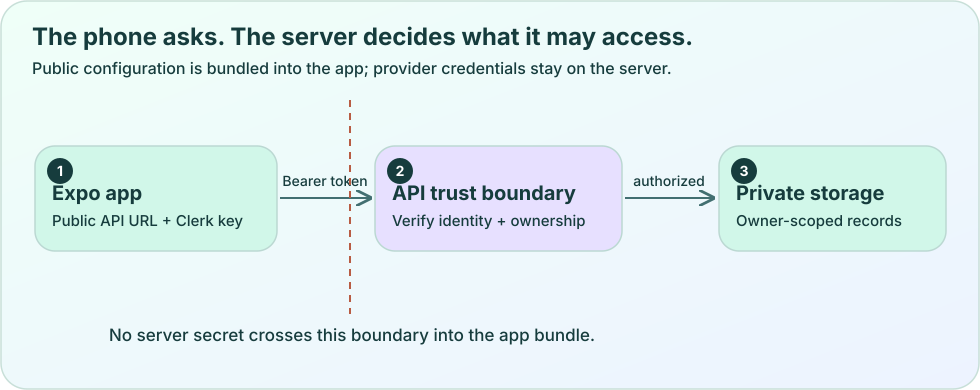

In [2]:
# Embedded original vector illustration; no external image files are required.
display(SVG(data='<svg xmlns="http://www.w3.org/2000/svg" width="980" height="390" viewBox="0 0 980 390" role="img" aria-labelledby="title desc"><title id="title">Client and server trust boundary</title><desc id="desc">The Expo app sends an authentication token to the API. The API verifies identity and ownership before reading private storage. A client query key is not authorization.</desc><defs>\n<linearGradient id="bg" x2="1" y2="1"><stop stop-color="#effff8"/><stop offset="1" stop-color="#edf3ff"/></linearGradient>\n<linearGradient id="leaf" x2="1" y2="1"><stop stop-color="#37e6b0"/><stop offset="1" stop-color="#07886c"/></linearGradient>\n<linearGradient id="glass" x2="1" y2="1"><stop stop-color="#fff" stop-opacity=".94"/><stop offset="1" stop-color="#e2efff" stop-opacity=".72"/></linearGradient>\n<linearGradient id="violet" x2="1" y2="1"><stop stop-color="#a58cff"/><stop offset="1" stop-color="#6550d9"/></linearGradient>\n<marker id="arrow" markerWidth="8" markerHeight="8" refX="7" refY="4" orient="auto"><path d="M0 0L8 4L0 8" fill="none" stroke="#426f71" stroke-width="1.4"/></marker>\n</defs><g font-family="system-ui,-apple-system,Segoe UI,sans-serif"><rect x="1" y="1" width="978" height="388" rx="26" fill="url(#bg)" stroke="#c8dfd8" stroke-width="1.5"/><text x="32" y="45" font-size="24" fill="#163c3d" font-weight="750" text-anchor="start">The phone asks. The server decides what it may access.</text><text x="32" y="74" font-size="16" fill="#163c3d" font-weight="500" text-anchor="start">Public configuration is bundled into the app; provider credentials stay on the server.</text><rect x="35" y="146" width="242" height="105" rx="20" fill="#d1f7e9" stroke="#bbd8d2" stroke-width="1.5"/><circle cx="60" cy="171" r="13" fill="#163c3d"/><text x="60" y="176" font-size="14" fill="#fff" font-weight="700" text-anchor="middle">1</text><text x="52" y="200" font-size="20" fill="#163c3d" font-weight="700" text-anchor="start">Expo app</text><text x="52" y="226" font-size="15" fill="#163c3d" font-weight="500" text-anchor="start">Public API URL + Clerk key</text><path d="M280 198L370 198" stroke="#426f71" stroke-width="2" fill="none" marker-end="url(#arrow)"/><text x="325.0" y="186.0" font-size="14" fill="#163c3d" font-weight="500" text-anchor="middle">Bearer token</text><rect x="375" y="146" width="247" height="105" rx="20" fill="#e7e0ff" stroke="#bbd8d2" stroke-width="1.5"/><circle cx="400" cy="171" r="13" fill="#163c3d"/><text x="400" y="176" font-size="14" fill="#fff" font-weight="700" text-anchor="middle">2</text><text x="392" y="200" font-size="20" fill="#163c3d" font-weight="700" text-anchor="start">API trust boundary</text><text x="392" y="226" font-size="15" fill="#163c3d" font-weight="500" text-anchor="start">Verify identity + ownership</text><path d="M625 198L713 198" stroke="#426f71" stroke-width="2" fill="none" marker-end="url(#arrow)"/><text x="669.0" y="186.0" font-size="14" fill="#163c3d" font-weight="500" text-anchor="middle">authorized</text><rect x="719" y="146" width="227" height="105" rx="20" fill="#d1f7e9" stroke="#bbd8d2" stroke-width="1.5"/><circle cx="744" cy="171" r="13" fill="#163c3d"/><text x="744" y="176" font-size="14" fill="#fff" font-weight="700" text-anchor="middle">3</text><text x="736" y="200" font-size="20" fill="#163c3d" font-weight="700" text-anchor="start">Private storage</text><text x="736" y="226" font-size="15" fill="#163c3d" font-weight="500" text-anchor="start">Owner-scoped records</text><path d="M350 100V314" stroke="#b85c43" stroke-width="2" stroke-dasharray="7 6"/><text x="352" y="341" font-size="17" fill="#163c3d" font-weight="500" text-anchor="middle">No server secret crosses this boundary into the app bundle.</text></g></svg>'))


> **Three different checks**
>
> Identity says who is asking. Authorization says which action that identity may perform. Validation says whether the submitted or returned data has an acceptable shape. Passing one check does not imply passing the other two.


## A TypeScript type cannot inspect a network response

TypeScript helps while you write and check your program. Its type annotations do not travel with a server response. Writing a type assertion after response.json() does not examine the response and cannot prevent a missing nickname or a malformed list from reaching your screen. This is why Plantopedia shares Zod schemas between its mobile client and server.

Read the following small teaching function as a complete boundary around one request. The caller provides a fresh token, a URL, and a schema. The function checks whether the token exists, checks the HTTP status, and then parses the returned unknown value. A schema failure becomes an error instead of a successful but broken view. In production, use the richer existing apiClient, which also handles structured errors, lifecycle cancellation, and request timeouts.

Validation does not establish ownership. A perfectly shaped plant can still belong to another account. Likewise, a valid token does not make an empty nickname acceptable. Keeping these checks distinct makes both the code and its error messages easier to reason about.


**Teaching example: readPrivate.ts**

Read this example here; TSX runs in Expo, while shell commands run in a terminal. This notebook uses a Python kernel.

```ts
import { z } from 'zod';

export async function readPrivate<T>(
  url: string,
  getToken: () => Promise<string | null>,
  schema: z.ZodType<T>,
  signal: AbortSignal,
): Promise<T> {
  const token = await getToken();
  if (!token) throw new Error('Sign in to open your cloud garden.');
  const response = await fetch(url, {
    headers: { Authorization: `Bearer ${token}` },
    signal,
  });
  if (!response.ok) throw new Error(`Request failed: ${response.status}`);
  const value: unknown = await response.json();
  return schema.parse(value);
}
```


## Public configuration is readable by the person running the app

An API base URL tells the app where to send requests. A Clerk publishable key identifies the client-facing application. These are appropriate public configuration values. Expo includes referenced EXPO_PUBLIC values in the compiled client bundle, so the word environment does not make them secret. Renaming a private provider key to EXPO_PUBLIC_PROVIDER_KEY would expose it.

Private provider keys, Clerk server credentials, and Firebase Admin credentials belong on the server. A screen asks Plantopedia's API for a permitted operation. The server authenticates the request and calls its configured provider. This also lets the server enforce limits and keep private credentials away from mobile bundles and browser developer tools.

Do not print a token to understand a failed request. Record a safe operation name, an error code, and whether the request was cancelled instead. A useful debugging message identifies the failing boundary without copying credentials or private plant notes into logs. The existing public configuration schema also restricts the allowed API URL form, so follow the repository's setup instructions rather than improvising an insecure device URL.


> **A phone has its own localhost**
>
> A localhost URL on a physical phone points at the phone. Follow the README's HTTPS phone-access workflow and public URL validation rules when reaching an API on your development computer.


## Make account changes a resource boundary

An account can change while a request is waiting. If Maya signs out and Leo signs in, Maya's late response must not become Leo's visible garden. An owner in the Query key separates cached results, but a key alone cannot cancel a microphone or stop pending work. Plantopedia creates owner-scoped API and voice resources inside SessionProvider, disposes the API scope on cleanup, and keys that provider by userId in the root layout.

The following screen excerpt uses the existing session and preferences providers. It explains that a guest action is local and offers a sign-in route for cloud features. It does not pretend that an interface message enforces server permissions. Guest storage and cloud storage are different paths, and this excerpt does not claim that signing in automatically migrates guest records.

This boundary should guide your own additions. Store drafts under the owner they were created for, include that owner in server-data cache keys, and close resources when their owner goes away. If a save has partly completed, preserve its original operation identity instead of silently replaying it as another account.


**Provider-dependent teaching excerpt: CloudNotice.tsx**

Read this example here; TSX runs in Expo, while shell commands run in a terminal. This notebook uses a Python kernel.

```tsx
import { Text, Button, View } from 'react-native';
import { useRouter } from 'expo-router';
import { useSessionApi } from '../services/session';

export function CloudNotice() {
  const { kind } = useSessionApi();
  const router = useRouter();
  if (kind === 'guest') {
    return (
      <View style={{ gap: 12 }}>
        <Text>Your guest garden is stored locally.</Text>
        <Button title="Sign in for cloud features"
          onPress={() => router.push('/login')} />
      </View>
    );
  }
  return <Text>Your cloud requests use your signed-in session.</Text>;
}
```


## Experiment: predict, change, explain

Choose a verified identity, a record owner, and a configuration value. Predict both the ownership decision and whether the value belongs in public app configuration or the server environment. Defaults are learner_a, learner_a, and api_url. This model assumes the identity was verified elsewhere; it neither validates a token nor classifies malformed API JSON. Response-shape validation is practiced in notebook 05.

The cell below is a bounded Python analogy of the lesson. Its fixtures do not call the app API, request permission, or certify device behavior. Its assertions check the stated model only.


In [3]:
# No real credentials or token decoding appear in this notebook.
def may_read(verified_identity, record_owner):
    return bool(verified_identity and verified_identity == record_owner)

def location_for(name):
    public = {'api_url', 'clerk_publishable_key'}
    server = {'provider_secret', 'firebase_admin_credentials'}
    if name in public:
        return 'public app configuration'
    if name in server:
        return 'server environment'
    raise ValueError('Unclassified value; inspect its intended trust boundary')

def explore_boundary(identity='learner_a', owner='learner_a', value='api_url'):
    print('Ownership decision:', 'allow' if may_read(identity, owner) else 'deny')
    print('Configuration location:', location_for(value))
    print('The server must establish verified_identity. Never trust a client-supplied owner.')

explore(explore_boundary, identity=['learner_a', 'learner_b', ''], owner=['learner_a', 'learner_b'], value=['api_url', 'clerk_publishable_key', 'provider_secret', 'firebase_admin_credentials'])
assert may_read('learner_a', 'learner_a')
assert not may_read('learner_b', 'learner_a')
assert not may_read('', '')
assert location_for('provider_secret') == 'server environment'


interactive(children=(Dropdown(description='identity', options=('learner_a', 'learner_b', ''), value='learner_…

## Make a prediction of your own

Can verified Learner B read a record owned by Learner A?

Replace `None` below. A blank answer reports **not attempted**; it is never counted as passing. The check gives feedback without interrupting “Run All.”


In [4]:
your_answer = None  # Replace with may_read('learner_b', 'learner_a').
if your_answer is None:
    print('Not attempted. Replace None, then rerun this cell.')
elif your_answer is False:
    print('Correct. '+'The verified caller and record owner differ, so the server must reject the request.')
else:
    print('Revisit your prediction. '+'The verified caller and record owner differ, so the server must reject the request.')


Not attempted. Replace None, then rerun this cell.


## Retrieve the ideas

**1. A screen hides Leo's plant from Maya. What still has to protect the record?**

1. The server must derive identity from verified credentials and enforce access to the requested record.
2. A hard-to-guess route is sufficient.
3. A TypeScript Plant annotation proves ownership.

**2. Where should a private plant-identification provider key live?**

1. In an EXPO_PUBLIC variable so every screen can reuse it.
2. In server-only configuration used by the authenticated API.
3. In a hidden Text component.

**3. The response has HTTP 200, but items is a string instead of an array. What should the client do?**

1. Treat it as a valid empty garden.
2. Cast it to PlantPage and continue.
3. Fail runtime validation and present a recoverable error.

Set each value in the next cell to your selected option number, starting at 1. You can change it and rerun for more feedback.


In [5]:
quiz = [{'question': "A screen hides Leo's plant from Maya. What still has to protect the record?", 'options': ['The server must derive identity from verified credentials and enforce access to the requested record.', 'A hard-to-guess route is sufficient.', 'A TypeScript Plant annotation proves ownership.'], 'answer': 0, 'explanation': 'Maya can construct an API request without using the screen. The server must verify the caller and enforce record access. An identifier is a locator, and a type annotation describes expected data; neither grants or denies permission.'}, {'question': 'Where should a private plant-identification provider key live?', 'options': ['In an EXPO_PUBLIC variable so every screen can reuse it.', 'In server-only configuration used by the authenticated API.', 'In a hidden Text component.'], 'answer': 1, 'explanation': "The mobile or web bundle can be inspected. Public variables and hidden components cannot protect a private key. The server holds the credential and performs authorized provider requests on the caller's behalf."}, {'question': 'The response has HTTP 200, but items is a string instead of an array. What should the client do?', 'options': ['Treat it as a valid empty garden.', 'Cast it to PlantPage and continue.', 'Fail runtime validation and present a recoverable error.'], 'answer': 2, 'explanation': "A successful HTTP status does not prove the body has the expected shape. Casting changes the compiler's assumption without checking the value. An explicit error preserves the difference between a real empty garden and invalid data."}]
answers = [None, None, None]  # Replace None with 1, 2, or 3.
correct = 0
for number, (question, answer) in enumerate(zip(quiz, answers), 1):
    if answer is None:
        print(f'{number}. Not attempted.')
    elif type(answer) is not int or answer not in range(1, len(question['options']) + 1):
        print(f'{number}. Choose a valid option number.')
    else:
        right = answer - 1 == question['answer']
        correct += int(right)
        print(f"{number}. {'Correct' if right else 'Revisit this idea'}. {question['explanation']}")
print(f'{correct} of {len(quiz)} correct; unanswered questions do not count as passing.')


1. Not attempted.
2. Not attempted.
3. Not attempted.
0 of 3 correct; unanswered questions do not count as passing.


## Build in Expo: Draw and defend a private request

Build a small request trace for opening one cloud plant, then write the client validation boundary using the existing PlantDetail schema. Work in your course copy and use synthetic identities only.

1. Draw Screen → apiClient → identity verification → owner-scoped plant lookup → validated response, and label where each check happens.
2. Read src/services/api.ts and identify the line that attaches the bearer token and the line that parses the returned JSON.
3. Write a teaching request function using PlantDetail.parse and a caller-supplied AbortSignal; do not hardcode a token.
4. Explain the outcome for no token, a valid token belonging to another owner, an invalid JSON body, and a request cancelled during sign-out.

### Check your result

- [ ] Your diagram separates identity, permission, and data shape.
- [ ] Your code treats network data as unknown until parsing succeeds.
- [ ] Your account-change explanation includes both cache separation and resource cleanup.
- [ ] No provider key, session token, or real user record appears in your exercise files.

Download the matching exercise bundle from the HTML course, or use the `exercises` folder if you downloaded the complete course. A notebooks-only download does not include that folder. Files under `docs/tutorials` do not become Expo routes until copied as instructed. The numbered workbook supplies a related concrete practice task; the inline exercise can ask you to extend it.


<details><summary>Hint</summary>

Follow the source of the owner on the server. If it came only from a form or a URL parameter, it cannot establish the caller's identity.

</details>

<details><summary>Worked reasoning / solution</summary>

```text
Use api.plant(id) from the existing session for the actual app. Its request helper obtains a token, attaches Authorization, checks response.ok, and parses PlantDetail. The server verifies identity and performs the lookup under that identity. A missing token fails authentication; another owner cannot select the private namespace; malformed JSON or schema mismatch fails parsing. On account change, disposing the old API aborts its lifecycle, while owner-prefixed Query keys prevent the new account from reusing the old account's cache. Guest data remains a separate local experience unless an explicit migration feature is designed.
```

</details>


## Explain it in your own words

If you add a public species catalogue next to private specimen notes, which fields can be public and which operations still need an authenticated owner? Explain your answer using the three checks from this lesson.

*Write your explanation in the Markdown cell below. Save the notebook to keep your work.*


My explanation:

<!-- Replace this comment with a connected explanation and an example. -->


## Find this idea in the app

- [src/services/api.ts](../../../src/services/api.ts) — The client obtains tokens, attaches credentials, checks status, and parses shared schemas.

- [src/services/session.tsx](../../../src/services/session.tsx) — Cloud and guest sessions create different owner-scoped resources.

- [server/src/http/identity.ts](../../../server/src/http/identity.ts) — The server verifies issuer, identity, and active session state.

- [server/src/application/plants.ts](../../../server/src/application/plants.ts) — Plant operations receive verified identity instead of trusting a submitted owner field.

- [src/config/public-env.ts](../../../src/config/public-env.ts) — The app validates public configuration and allowed API URL forms.

Repository links require this notebook to remain in the checkout’s `docs/tutorials/notebooks` folder. Downloaded notebooks still contain every explanation and embedded diagram.

## Primary documentation

- [Expo: environment variables](https://docs.expo.dev/guides/environment-variables/)
- [TanStack Query v5: query keys](https://tanstack.com/query/latest/docs/framework/react/guides/query-keys)
- [Clerk: manually verify session tokens](https://clerk.com/docs/guides/sessions/manual-jwt-verification)


## Carry these ideas forward

- A mobile interface helps people make choices, while the server enforces private data access.
- Shared runtime schemas verify data that TypeScript alone cannot inspect.
- Public Expo configuration is bundled into the client, and account changes require resource cleanup as well as cache separation.
